In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split,RandomizedSearchCV,GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier,GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("student_sleep_mental_health_2026.csv")
df.head()

,student_id,age,gender,education_level,avg_sleep_hours,screen_time_hours,social_media_hours,study_hours_per_day,exercise_hours_per_week,caffeine_drinks_per_day,stress_level,anxiety_score,gpa,uses_sleep_app,feels_burned_out
0,1,21,Non-binary,High School,8.0,4.9,3.7,5.0,4.8,1,7,7,3.35,False,True
1,2,19,Female,Undergraduate,7.3,7.7,5.3,2.8,4.2,1,8,8,2.81,True,True
2,3,19,Male,Undergraduate,6.1,7.3,3.6,3.6,5.8,1,8,10,3.01,True,True
3,4,16,Male,High School,6.2,7.4,4.0,0.4,2.0,4,9,10,2.76,False,True
4,5,20,Male,Graduate,5.6,12.5,8.3,2.6,6.2,3,10,10,2.67,False,True


In [3]:
df["gender"].value_counts()

gender
Female               1410
Male                 1406
Non-binary            110
Prefer not to say      74
Name: count, dtype: int64

In [4]:
def gender_fill_other(gend):
    if gend == "Female" or gend == "Male":
        return gend
    else:
        return "Other"

df["gender"] = df["gender"].apply(gender_fill_other)
df["gender"].value_counts()

gender
Female    1410
Male      1406
Other      184
Name: count, dtype: int64

In [5]:
df[["uses_sleep_app","feels_burned_out"]] = df[["uses_sleep_app","feels_burned_out"]].astype(int)
df.head()

,student_id,age,gender,education_level,avg_sleep_hours,screen_time_hours,social_media_hours,study_hours_per_day,exercise_hours_per_week,caffeine_drinks_per_day,stress_level,anxiety_score,gpa,uses_sleep_app,feels_burned_out
0,1,21,Other,High School,8.0,4.9,3.7,5.0,4.8,1,7,7,3.35,0,1
1,2,19,Female,Undergraduate,7.3,7.7,5.3,2.8,4.2,1,8,8,2.81,1,1
2,3,19,Male,Undergraduate,6.1,7.3,3.6,3.6,5.8,1,8,10,3.01,1,1
3,4,16,Male,High School,6.2,7.4,4.0,0.4,2.0,4,9,10,2.76,0,1
4,5,20,Male,Graduate,5.6,12.5,8.3,2.6,6.2,3,10,10,2.67,0,1


In [6]:
df = pd.get_dummies(df,columns=["gender","education_level"],drop_first=True,dtype=int)
df.head()

,student_id,age,avg_sleep_hours,screen_time_hours,social_media_hours,study_hours_per_day,exercise_hours_per_week,caffeine_drinks_per_day,stress_level,anxiety_score,gpa,uses_sleep_app,feels_burned_out,gender_Male,gender_Other,education_level_High School,education_level_Undergraduate
0,1,21,8.0,4.9,3.7,5.0,4.8,1,7,7,3.35,0,1,0,1,1,0
1,2,19,7.3,7.7,5.3,2.8,4.2,1,8,8,2.81,1,1,0,0,0,1
2,3,19,6.1,7.3,3.6,3.6,5.8,1,8,10,3.01,1,1,1,0,0,1
3,4,16,6.2,7.4,4.0,0.4,2.0,4,9,10,2.76,0,1,1,0,1,0
4,5,20,5.6,12.5,8.3,2.6,6.2,3,10,10,2.67,0,1,1,0,0,0


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 17 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   student_id                     3000 non-null   int64  
 1   age                            3000 non-null   int64  
 2   avg_sleep_hours                3000 non-null   float64
 3   screen_time_hours              3000 non-null   float64
 4   social_media_hours             3000 non-null   float64
 5   study_hours_per_day            3000 non-null   float64
 6   exercise_hours_per_week        3000 non-null   float64
 7   caffeine_drinks_per_day        3000 non-null   int64  
 8   stress_level                   3000 non-null   int64  
 9   anxiety_score                  3000 non-null   int64  
 10  gpa                            3000 non-null   float64
 11  uses_sleep_app                 3000 non-null   int64  
 12  feels_burned_out               3000 non-null   i

In [9]:
df["anxiety_score"].unique()

array([ 7,  8, 10,  6,  5,  3,  4,  9,  1,  2])

In [10]:
def anxiety_score_bool(anxi):
    if anxi >= 1 and anxi <= 5:
        return 0
    else:
        return 1

df["anxiety"] = df["anxiety_score"].apply(anxiety_score_bool)
df.head()


,student_id,age,avg_sleep_hours,screen_time_hours,social_media_hours,study_hours_per_day,exercise_hours_per_week,caffeine_drinks_per_day,stress_level,anxiety_score,gpa,uses_sleep_app,feels_burned_out,gender_Male,gender_Other,education_level_High School,education_level_Undergraduate,anxiety
0,1,21,8.0,4.9,3.7,5.0,4.8,1,7,7,3.35,0,1,0,1,1,0,1
1,2,19,7.3,7.7,5.3,2.8,4.2,1,8,8,2.81,1,1,0,0,0,1,1
2,3,19,6.1,7.3,3.6,3.6,5.8,1,8,10,3.01,1,1,1,0,0,1,1
3,4,16,6.2,7.4,4.0,0.4,2.0,4,9,10,2.76,0,1,1,0,1,0,1
4,5,20,5.6,12.5,8.3,2.6,6.2,3,10,10,2.67,0,1,1,0,0,0,1


In [11]:
df["anxiety"].unique()

array([1, 0])

In [12]:
df.drop(["student_id","anxiety_score","uses_sleep_app","caffeine_drinks_per_day","study_hours_per_day"],axis=1,inplace=True)
df.head()

,age,avg_sleep_hours,screen_time_hours,social_media_hours,exercise_hours_per_week,stress_level,gpa,feels_burned_out,gender_Male,gender_Other,education_level_High School,education_level_Undergraduate,anxiety
0,21,8.0,4.9,3.7,4.8,7,3.35,1,0,1,1,0,1
1,19,7.3,7.7,5.3,4.2,8,2.81,1,0,0,0,1,1
2,19,6.1,7.3,3.6,5.8,8,3.01,1,1,0,0,1,1
3,16,6.2,7.4,4.0,2.0,9,2.76,1,1,0,1,0,1
4,20,5.6,12.5,8.3,6.2,10,2.67,1,1,0,0,0,1


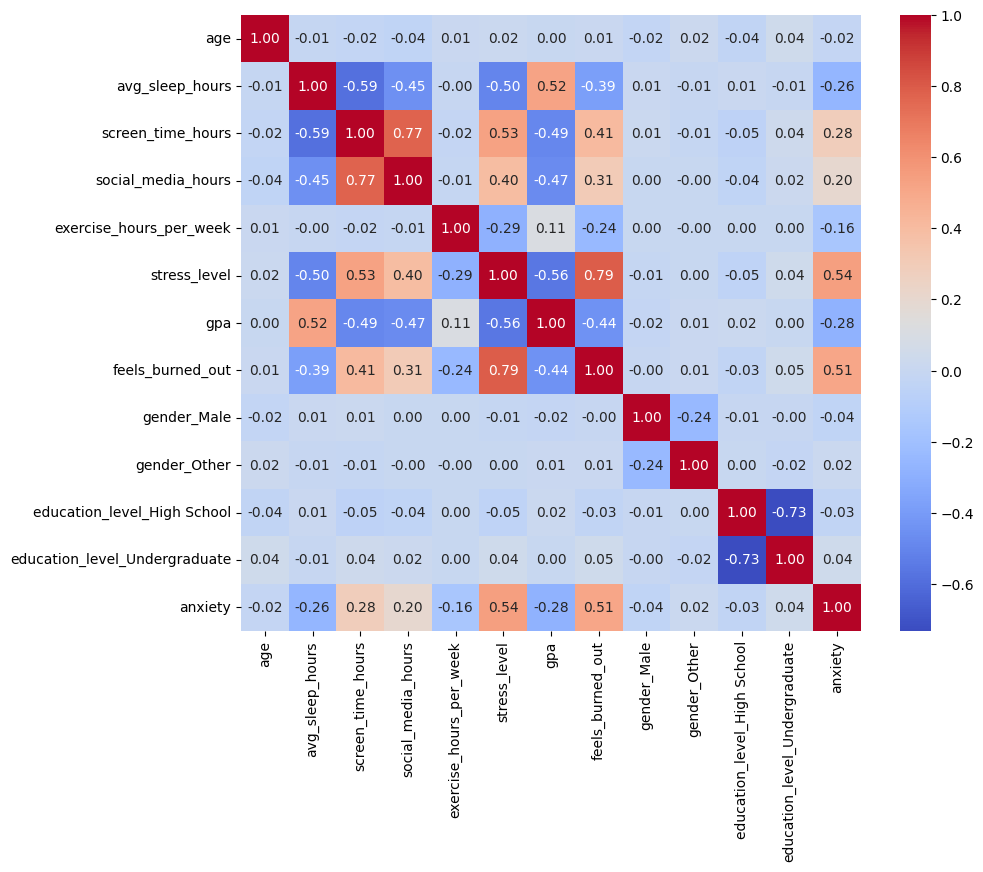

In [13]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.show()

In [14]:
df.describe()

,age,avg_sleep_hours,screen_time_hours,social_media_hours,exercise_hours_per_week,stress_level,gpa,feels_burned_out,gender_Male,gender_Other,education_level_High School,education_level_Undergraduate,anxiety
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,19.445000,7.414067,6.494667,3.575033,3.541900,7.216667,3.244487,0.679667,0.468667,0.061333,0.296333,0.560333,0.785000
std,2.924921,0.971279,2.165014,1.563631,2.336889,1.572433,0.379404,0.466682,0.499100,0.239981,0.456716,0.496429,0.410891
min,14.000000,4.400000,1.000000,0.000000,0.000000,1.000000,1.970000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,17.000000,6.800000,5.000000,2.500000,1.800000,6.000000,2.980000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
50%,19.000000,7.400000,6.500000,3.600000,3.400000,7.000000,3.245000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000
75%,21.000000,8.100000,8.000000,4.600000,5.100000,8.000000,3.510000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000
max,29.000000,10.900000,13.600000,9.000000,11.300000,10.000000,4.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [15]:
df.shape

(3000, 13)

In [16]:
df.columns

Index(['age', 'avg_sleep_hours', 'screen_time_hours', 'social_media_hours',
       'exercise_hours_per_week', 'stress_level', 'gpa', 'feels_burned_out',
       'gender_Male', 'gender_Other', 'education_level_High School',
       'education_level_Undergraduate', 'anxiety'],
      dtype='object')

In [17]:
df.isnull().sum()

age                              0
avg_sleep_hours                  0
screen_time_hours                0
social_media_hours               0
exercise_hours_per_week          0
stress_level                     0
gpa                              0
feels_burned_out                 0
gender_Male                      0
gender_Other                     0
education_level_High School      0
education_level_Undergraduate    0
anxiety                          0
dtype: int64

In [18]:
df.duplicated().sum()

np.int64(0)

In [19]:
df.corr()

,age,avg_sleep_hours,screen_time_hours,social_media_hours,exercise_hours_per_week,stress_level,gpa,feels_burned_out,gender_Male,gender_Other,education_level_High School,education_level_Undergraduate,anxiety
age,1.000000,-0.008671,-0.024121,-0.038311,0.006877,0.015134,0.004684,0.007975,-0.022994,0.024759,-0.035346,0.039718,-0.016085
avg_sleep_hours,-0.008671,1.000000,-0.587266,-0.453081,-0.002421,-0.495939,0.522262,-0.386412,0.005587,-0.005848,0.005634,-0.008192,-0.264128
screen_time_hours,-0.024121,-0.587266,1.000000,0.772260,-0.020434,0.528283,-0.491977,0.408392,0.013793,-0.011564,-0.049119,0.036939,0.283957
social_media_hours,-0.038311,-0.453081,0.772260,1.000000,-0.011911,0.396700,-0.469141,0.307210,0.002821,-0.000627,-0.037869,0.020262,0.200849
exercise_hours_per_week,0.006877,-0.002421,-0.020434,-0.011911,1.000000,-0.288149,0.107764,-0.242224,0.004371,-0.000065,0.000797,0.000048,-0.162059
stress_level,0.015134,-0.495939,0.528283,0.396700,-0.288149,1.000000,-0.558041,0.794829,-0.011741,0.001001,-0.048110,0.041769,0.544861
gpa,0.004684,0.522262,-0.491977,-0.469141,0.107764,-0.558041,1.000000,-0.443721,-0.021216,0.005217,0.017591,0.004971,-0.280661
feels_burned_out,0.007975,-0.386412,0.408392,0.307210,-0.242224,0.794829,-0.443721,1.000000,-0.003738,0.008757,-0.034767,0.045309,0.506691
gender_Male,-0.022994,0.005587,0.013793,0.002821,0.004371,-0.011741,-0.021216,-0.003738,1.000000,-0.240072,-0.006794,-0.003807,-0.040177
gender_Other,0.024759,-0.005848,-0.011564,-0.000627,-0.000065,0.001001,0.005217,0.008757,-0.240072,1.000000,0.004486,-0.019876,0.015420


In [20]:
df.head()

,age,avg_sleep_hours,screen_time_hours,social_media_hours,exercise_hours_per_week,stress_level,gpa,feels_burned_out,gender_Male,gender_Other,education_level_High School,education_level_Undergraduate,anxiety
0,21,8.0,4.9,3.7,4.8,7,3.35,1,0,1,1,0,1
1,19,7.3,7.7,5.3,4.2,8,2.81,1,0,0,0,1,1
2,19,6.1,7.3,3.6,5.8,8,3.01,1,1,0,0,1,1
3,16,6.2,7.4,4.0,2.0,9,2.76,1,1,0,1,0,1
4,20,5.6,12.5,8.3,6.2,10,2.67,1,1,0,0,0,1


In [21]:
scaler_cols = [	"age","avg_sleep_hours","screen_time_hours","social_media_hours","exercise_hours_per_week","stress_level","gpa"]

scaler = StandardScaler()
df[scaler_cols] = scaler.fit_transform(df[scaler_cols])
df.head()

,age,avg_sleep_hours,screen_time_hours,social_media_hours,exercise_hours_per_week,stress_level,gpa,feels_burned_out,gender_Male,gender_Other,education_level_High School,education_level_Undergraduate,anxiety
0,0.531727,0.603360,-0.736684,0.079934,0.538455,-0.137814,0.278150,1,0,1,1,0,1
1,-0.152166,-0.117459,0.556825,1.103364,0.281661,0.498249,-1.145374,1,0,0,0,1,1
2,-0.152166,-1.353149,0.372038,0.015970,0.966446,0.498249,-0.618143,1,1,0,0,1,1
3,-1.178006,-1.250175,0.418235,0.271827,-0.659919,1.134312,-1.277182,1,1,0,1,0,1
4,0.189780,-1.868020,2.774270,3.022295,1.137642,1.770375,-1.514436,1,1,0,0,0,1


In [22]:
X = df.drop("anxiety",axis=1)
y = df["anxiety"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

In [23]:
model = XGBClassifier()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy_score(y_test, y_pred)

0.797979797979798

In [24]:
models = {
    "logistic_regression": LogisticRegression(),
    "Decision_tree": DecisionTreeClassifier(),
    "knn": KNeighborsClassifier(),
    "AdaBoostClassifier": AdaBoostClassifier(),
    "XGBClassifier": XGBClassifier(),
    "GradientBoostingClassifier": GradientBoostingClassifier(),
    "RandomForestClassifier": RandomForestClassifier()
}

In [25]:
results = []

for name,model in models.items():
    model.fit(X_train,y_train)
    y_pred = model.predict(X_test)
    results.append({
        'model':name,
        'accuracy':accuracy_score(y_test,y_pred)
    })
df_results = pd.DataFrame(results)

df_results



,model,accuracy
0,logistic_regression,0.829293
1,Decision_tree,0.798990
2,knn,0.812121
3,AdaBoostClassifier,0.809091
4,XGBClassifier,0.797980
5,GradientBoostingClassifier,0.824242
6,RandomForestClassifier,0.819192


In [26]:
model = models["XGBClassifier"]

In [27]:
classifier = RandomizedSearchCV(
    (model),
    {
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.05, 0.1],
    'n_estimators': [100, 200, 300],
    'min_child_weight': [1, 3, 5],
    'subsample': [0.7, 0.8, 0.9],
    'colsample_bytree': [0.7, 0.8, 0.9],
    'reg_lambda': [0.1, 1.0, 10.0],
    'reg_alpha': [0, 0.1, 1.0]
    },
    cv=5,
    n_jobs=-1,
    return_train_score=False,
)
classifier.fit(X_train, y_train)
result = pd.DataFrame(classifier.cv_results_)
result


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_subsample,param_reg_lambda,param_reg_alpha,param_n_estimators,param_min_child_weight,param_max_depth,...,param_colsample_bytree,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.169659,0.021928,0.017017,0.010132,0.8,1.0,0.1,100,3,3,...,0.9,"{'subsample': 0.8, 'reg_lambda': 1.0, 'reg_alp...",0.805970,0.823383,0.825871,0.813433,0.803483,0.814428,0.008983,4
1,0.130026,0.013443,0.011105,0.004936,0.7,0.1,0.1,100,3,5,...,0.8,"{'subsample': 0.7, 'reg_lambda': 0.1, 'reg_alp...",0.778607,0.833333,0.805970,0.791045,0.796020,0.800995,0.018415,9
2,0.185357,0.008007,0.018341,0.007206,0.7,0.1,0.0,200,5,5,...,0.8,"{'subsample': 0.7, 'reg_lambda': 0.1, 'reg_alp...",0.791045,0.830846,0.815920,0.798507,0.776119,0.802488,0.019114,8
3,0.150259,0.010214,0.010934,0.010244,0.8,1.0,0.1,200,5,3,...,0.9,"{'subsample': 0.8, 'reg_lambda': 1.0, 'reg_alp...",0.810945,0.833333,0.820896,0.820896,0.810945,0.819403,0.008265,2
4,0.112579,0.006616,0.007319,0.000882,0.9,10.0,0.0,100,1,5,...,0.8,"{'subsample': 0.9, 'reg_lambda': 10.0, 'reg_al...",0.800995,0.833333,0.793532,0.805970,0.805970,0.807960,0.013479,5
5,0.187914,0.022769,0.006826,0.001182,0.9,0.1,0.1,200,1,4,...,0.8,"{'subsample': 0.9, 'reg_lambda': 0.1, 'reg_alp...",0.798507,0.825871,0.798507,0.796020,0.798507,0.803483,0.011235,7
6,0.206709,0.022849,0.018204,0.011673,0.9,0.1,1.0,200,1,4,...,0.9,"{'subsample': 0.9, 'reg_lambda': 0.1, 'reg_alp...",0.818408,0.825871,0.833333,0.825871,0.813433,0.823383,0.006858,1
7,0.078971,0.017955,0.028979,0.018603,0.8,10.0,1.0,100,3,3,...,0.8,"{'subsample': 0.8, 'reg_lambda': 10.0, 'reg_al...",0.805970,0.825871,0.815920,0.820896,0.810945,0.815920,0.007036,3
8,0.242455,0.015938,0.010521,0.002320,0.9,10.0,1.0,300,3,3,...,0.7,"{'subsample': 0.9, 'reg_lambda': 10.0, 'reg_al...",0.813433,0.823383,0.798507,0.808458,0.796020,0.807960,0.010000,5
9,0.298684,0.038585,0.010633,0.003227,0.9,0.1,1.0,300,3,5,...,0.9,"{'subsample': 0.9, 'reg_lambda': 0.1, 'reg_alp...",0.793532,0.818408,0.798507,0.796020,0.783582,0.798010,0.011389,10


In [29]:
result["params"][3]

{'subsample': 0.8,
 'reg_lambda': 1.0,
 'reg_alpha': 0.1,
 'n_estimators': 200,
 'min_child_weight': 5,
 'max_depth': 3,
 'learning_rate': 0.01,
 'colsample_bytree': 0.9}

In [34]:
Xgb_model = XGBClassifier(
    subsample= 0.8,
    reg_lambda= 1.0,
    reg_alpha= 0.1,
    n_estimators= 200,
    min_child_weight= 5,
    max_depth= 3,
    learning_rate= 0.01,
    colsample_bytree= 0.9
)
Xgb_model.fit(X_train,y_train)
y_pred = Xgb_model.predict(X_test)
accuracy_score(y_test,y_pred)


0.8313131313131313

In [35]:
from joblib import dump

dump(Xgb_model,"model.pkl")
dump(scaler,"scaler.pkl")
dump(X.columns.tolist(),"columns.pkl")

['columns.pkl']